In [109]:
import Pkg
Pkg.add("Plots")
Pkg.add("Distributions")

   Resolving package versions...
     Project No packages added to or removed from `C:\Users\Magis\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\Magis\.julia\environments\v1.12\Manifest.toml`
   Resolving package versions...
     Project No packages added to or removed from `C:\Users\Magis\.julia\environments\v1.12\Project.toml`
    Manifest No packages added to or removed from `C:\Users\Magis\.julia\environments\v1.12\Manifest.toml`


In [110]:
using Plots
using Random
using Statistics
using Distributions

Random.seed!(999999)
gr()

Plots.GRBackend()

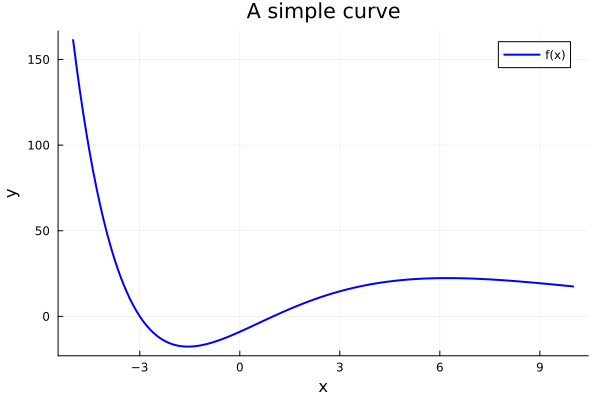

In [111]:
f(x) = (3 * x^2 + 6 * x - 9) * exp(-0.3 * x)
x_function = collect(range(-5, stop=10, length=151))
y_function = f.(x_function)

p_function = plot(
    x_function, y_function,
    title="A simple curve",
    xlabel="x",
    ylabel="y",
    label="f(x)",
    color=:blue,
    linewidth=2
)
display(p_function)

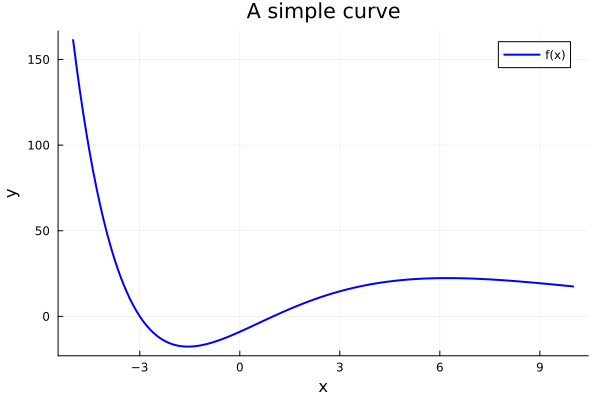

In [112]:
p_function_ru = plot(
    x_function, y_function,
    title="A simple curve",
    xlabel="x",
    ylabel="y",
    label="f(x)",
    color=:blue,
    linewidth=2
)
display(p_function_ru)

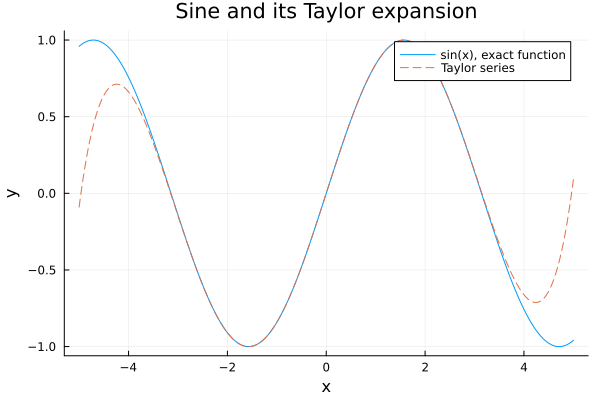

In [113]:
sin_theor(x) = sin(x)
sin_taylor(x) = sum((-1)^i * x^(2 * i + 1) / factorial(2 * i + 1) for i in 0:4)

x_sin = collect(range(-5, stop=5, length=500))
p_sin = plot(
    x_sin, sin_theor.(x_sin),
    label="sin(x), exact function",
    xlabel="x",
    ylabel="y",
    title="Sine and its Taylor expansion"
)
plot!(p_sin, x_sin, sin_taylor.(x_sin), label="Taylor series", linestyle=:dash)
display(p_sin)

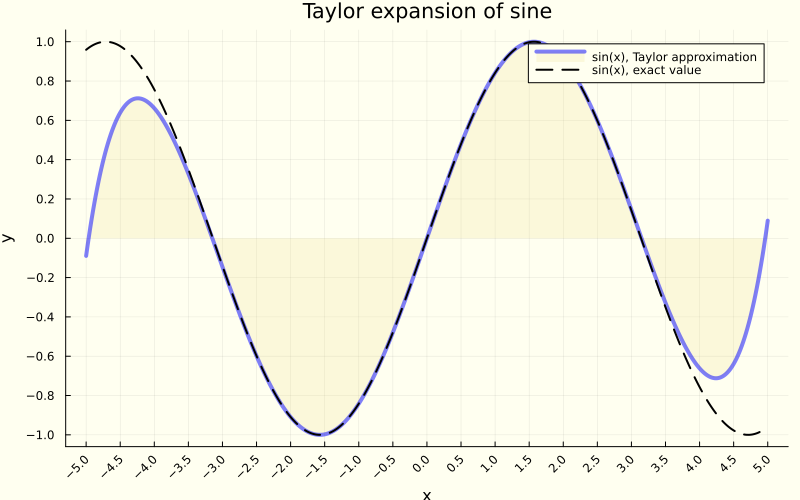

In [114]:
p_taylor_style = plot(
    x_sin, sin_taylor.(x_sin),
    label="sin(x), Taylor approximation",
    line=(:blue, 0.5, 4, :solid),
    size=(800, 500),
    xticks=-5:0.5:5,
    yticks=-1:0.2:1,
    xlabel="x",
    ylabel="y",
    title="Taylor expansion of sine",
    xrotation=45,
    fillrange=0,
    fillalpha=0.2,
    fillcolor=:lightgoldenrod,
    background_color=:ivory
)
plot!(p_taylor_style, x_sin, sin_theor.(x_sin), label="sin(x), exact value", line=(:black, 1.0, 2, :dash))
display(p_taylor_style)

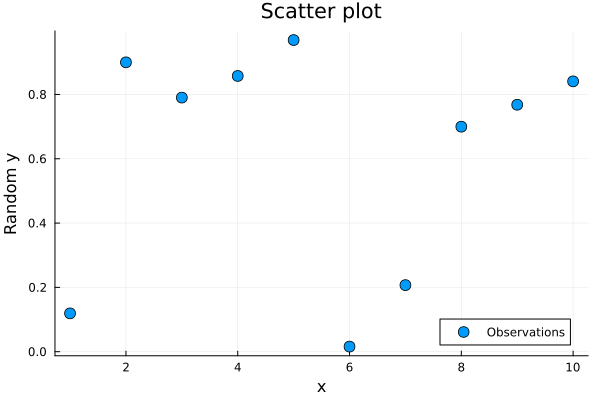

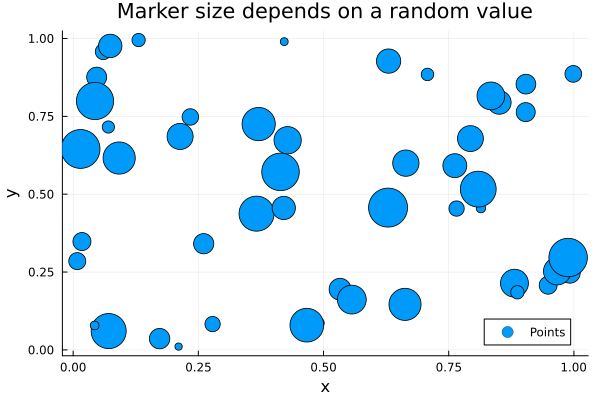

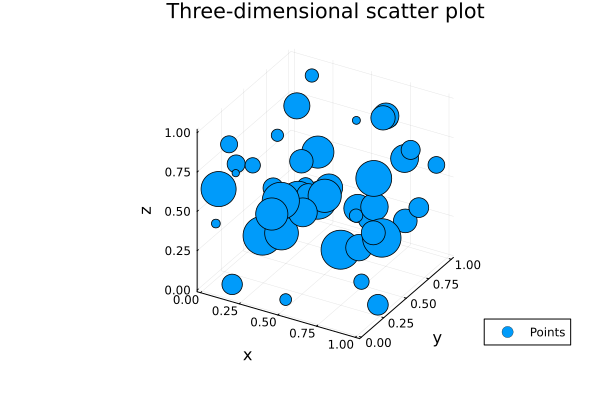

In [115]:
x_scatter = collect(range(1, stop=10, length=10))
y_scatter = rand(10)

p_scatter = scatter(
    x_scatter, y_scatter,
    title="Scatter plot",
    xlabel="x",
    ylabel="Random y",
    label="Observations",
    markersize=6
)
display(p_scatter)

n_scatter = 50
x_scatter_50 = rand(n_scatter)
y_scatter_50 = rand(n_scatter)
marker_sizes = 3 .+ 20 .* rand(n_scatter)
p_scatter_size = scatter(
    x_scatter_50, y_scatter_50,
    markersize=marker_sizes,
    xlabel="x",
    ylabel="y",
    title="Marker size depends on a random value",
    label="Points"
)
display(p_scatter_size)

z_scatter_50 = rand(n_scatter)
p_scatter_3d = scatter(
    x_scatter_50, y_scatter_50, z_scatter_50,
    markersize=marker_sizes,
    xlabel="x",
    ylabel="y",
    zlabel="z",
    title="Three-dimensional scatter plot",
    label="Points"
)
display(p_scatter_3d)

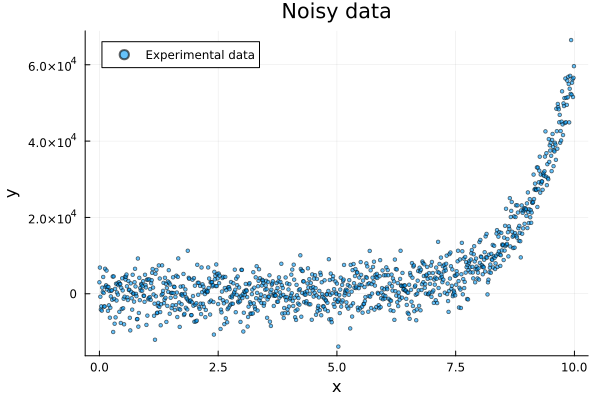

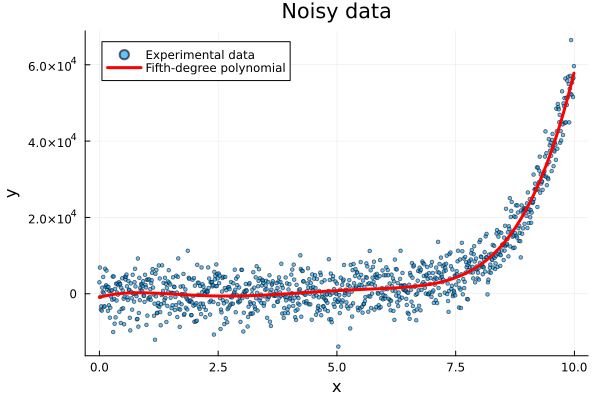

In [116]:
x_data = collect(0:0.01:9.99)
y_data = exp.(1 .+ x_data) .+ 4000 .* randn(length(x_data))

p_data = scatter(
    x_data, y_data,
    markersize=2,
    alpha=0.6,
    label="Experimental data",
    xlabel="x",
    ylabel="y",
    title="Noisy data"
)
display(p_data)

A_poly = hcat(
    ones(length(x_data)),
    x_data,
    x_data.^2,
    x_data.^3,
    x_data.^4,
    x_data.^5
)
coefficients = A_poly \ y_data

y_poly = sum(coefficients[j] .* x_data.^(j - 1) for j in 1:6)
plot!(p_data, x_data, y_poly, linewidth=3, color=:red, label="Fifth-degree polynomial")
display(p_data)

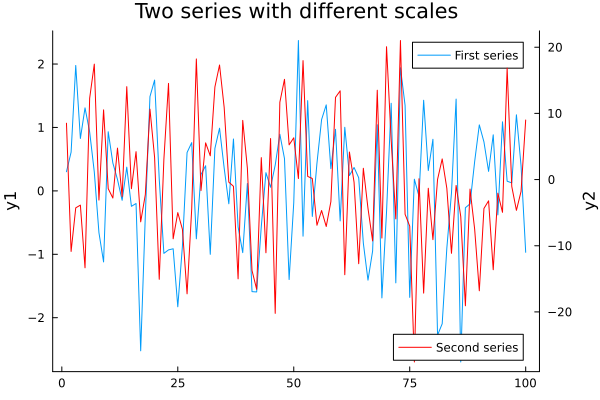

In [117]:
y1_random = randn(100)
p_two_axes = plot(
    y1_random,
    ylabel="y1",
    label="First series",
    title="Two series with different scales",
    legend=:topright,
    grid=false
)
y2_random = 10 .* randn(100)
plot!(twinx(), y2_random, color=:red, ylabel="y2", label="Second series", legend=:bottomright, grid=false)
display(p_two_axes)

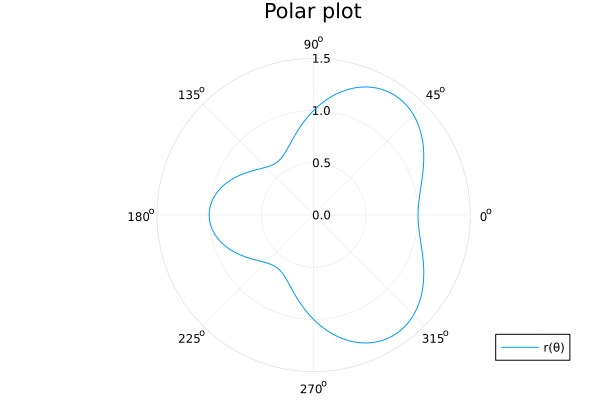

In [118]:
r_polar(theta) = 1 + cos(theta) * sin(theta)^2
theta_polar = range(0, stop=2pi, length=500)
p_polar = plot(
    theta_polar, r_polar.(theta_polar),
    proj=:polar,
    lims=(0, 1.5),
    title="Polar plot",
    label="r(θ)"
)
display(p_polar)

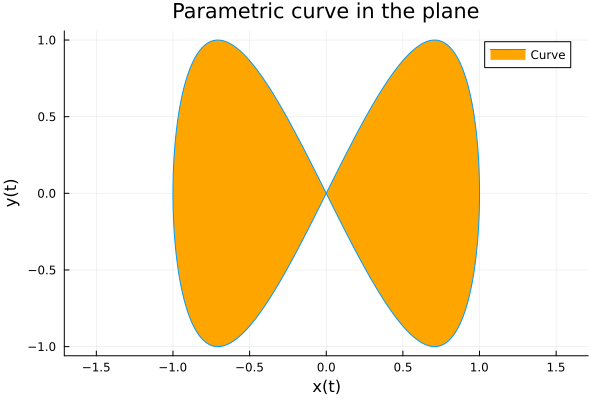

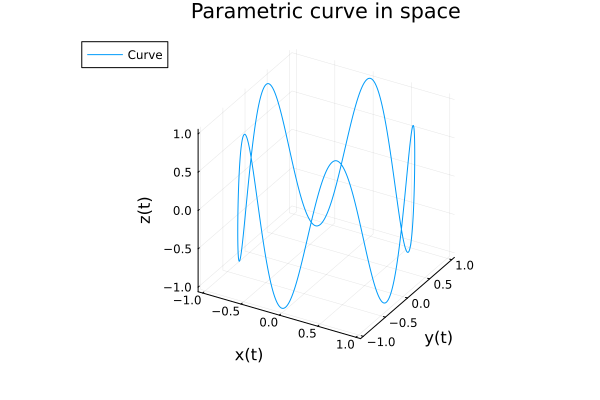

In [119]:
t_param = range(0, stop=2pi, length=500)
x_param = sin.(t_param)
y_param = sin.(2 .* t_param)
p_param_2d = plot(
    x_param, y_param,
    xlabel="x(t)",
    ylabel="y(t)",
    title="Parametric curve in the plane",
    label="Curve",
    fill=(0, :orange),
    aspect_ratio=:equal
)
display(p_param_2d)

x_param_3d = cos.(t_param)
y_param_3d = sin.(t_param)
z_param_3d = sin.(5 .* t_param)
p_param_3d = plot(
    x_param_3d, y_param_3d, z_param_3d,
    xlabel="x(t)",
    ylabel="y(t)",
    zlabel="z(t)",
    title="Parametric curve in space",
    label="Curve"
)
display(p_param_3d)

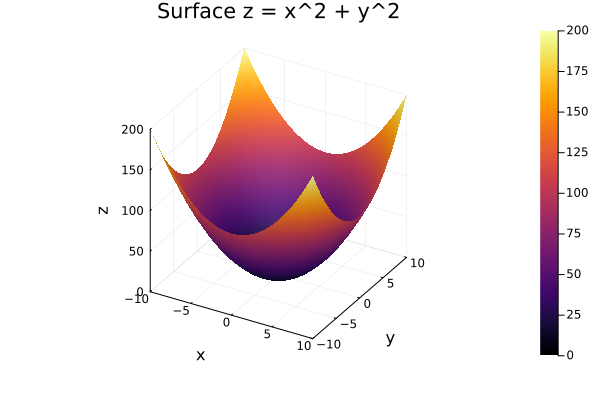

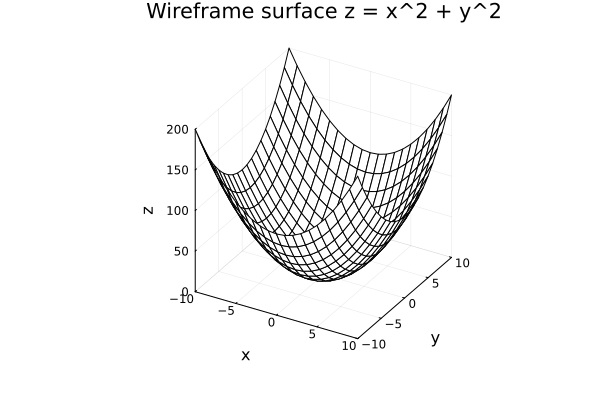

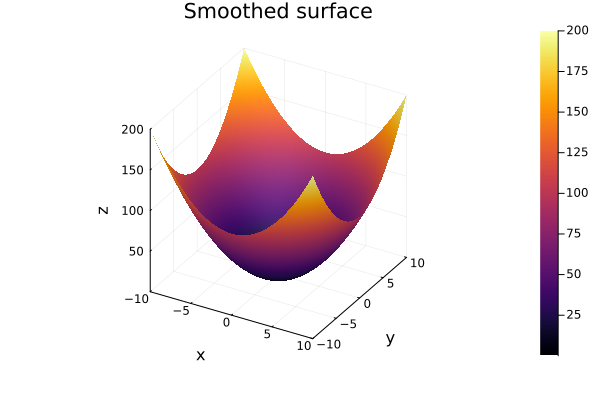

In [120]:
f_surface(x, y) = x^2 + y^2
x_surface = -10:1:10
y_surface = -10:1:10
Z_surface = [f_surface(x, y) for x in x_surface, y in y_surface]

p_surface = surface(
    x_surface, y_surface, Z_surface,
    xlabel="x",
    ylabel="y",
    zlabel="z",
    title="Surface z = x^2 + y^2",
    label="Surface"
)
display(p_surface)

p_wireframe = plot(
    x_surface, y_surface, Z_surface,
    linetype=:wireframe,
    xlabel="x",
    ylabel="y",
    zlabel="z",
    title="Wireframe surface z = x^2 + y^2",
    label="Wireframe"
)
display(p_wireframe)

x_smooth = range(-10, stop=10, length=100)
y_smooth = range(-10, stop=10, length=100)
Z_smooth = [f_surface(x, y) for x in x_smooth, y in y_smooth]
p_surface_smooth = surface(x_smooth, y_smooth, Z_smooth, title="Smoothed surface", xlabel="x", ylabel="y", zlabel="z")
display(p_surface_smooth)

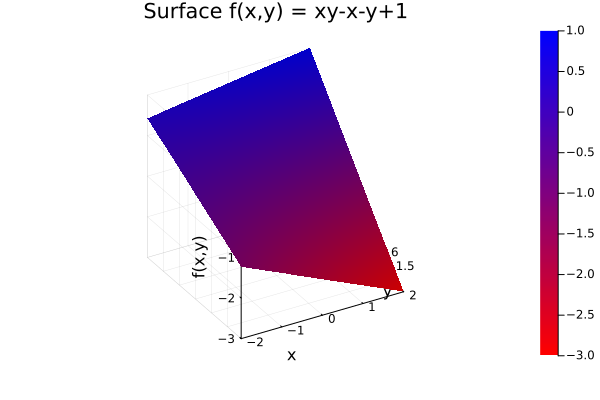

In [121]:
f_surface_2(x, y) = x * y - x - y + 1
x_surface_2 = range(-2, stop=2, length=100)
y_surface_2 = range(sqrt(2), stop=2, length=100)
Z_surface_2 = [f_surface_2(x, y) for x in x_surface_2, y in y_surface_2]

p_surface_2 = surface(
    x_surface_2, y_surface_2, Z_surface_2,
    color=cgrad([:red, :blue]),
    camera=(-30, 30),
    xlabel="x",
    ylabel="y",
    zlabel="f(x,y)",
    title="Surface f(x,y) = xy-x-y+1"
)
display(p_surface_2)

In [122]:
g_level(x, y) = (3 * x + y^2) * abs(sin(x) + cos(y))
x_level = collect(1:0.5:20)
y_level = collect(1:0.5:10)
Z_level = [g_level(x, y) for x in x_level, y in y_level]

p_level_surface = surface(x_level, y_level, Z_level, xlabel="x", ylabel="y", zlabel="g(x,y)", title="Surface of g(x,y)")
display(p_level_surface)

p_contour = contour(x_level, y_level, Z_level, xlabel="x", ylabel="y", title="Contour lines of g(x,y)", label="Levels")
display(p_contour)

p_contour_fill = contour(x_level, y_level, Z_level, fill=true, xlabel="x", ylabel="y", title="Filled contour plot")
display(p_contour_fill)

LoadError: Arrays have incorrect length or dimension.

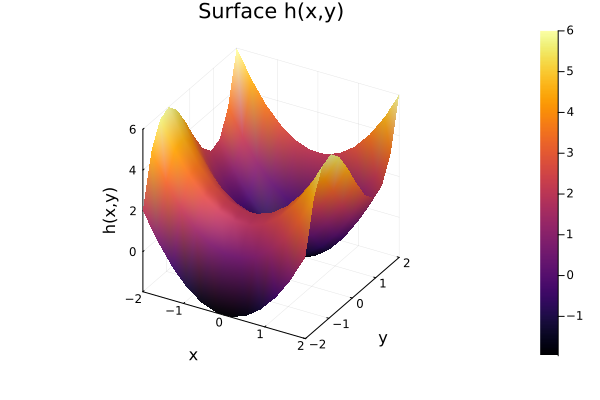

print device already activated


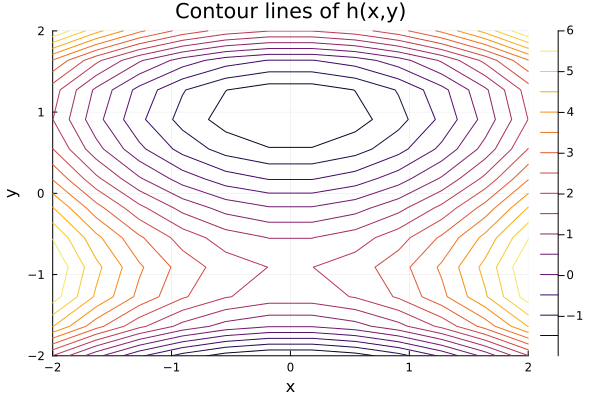

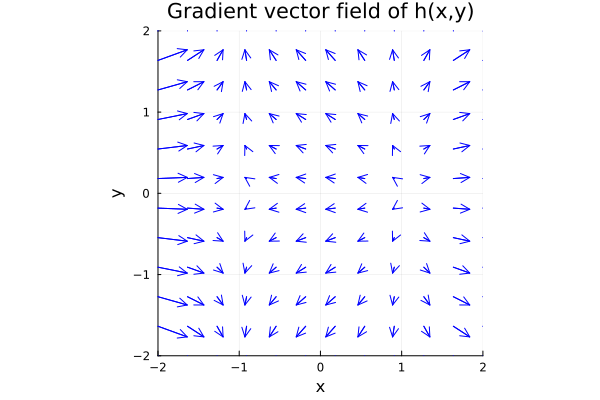

In [123]:
h_field(x, y) = x^3 - 3 * x + y^2
x_field = collect(range(-2, stop=2, length=12))
y_field = collect(range(-2, stop=2, length=12))
Z_field = [h_field(x, y) for x in x_field, y in y_field]

p_field_surface = surface(x_field, y_field, Z_field, xlabel="x", ylabel="y", zlabel="h(x,y)", title="Surface h(x,y)")
display(p_field_surface)

p_field_contour = contour(x_field, y_field, Z_field, xlabel="x", ylabel="y", title="Contour lines of h(x,y)")
display(p_field_contour)

x_points_field = repeat(x_field, inner=length(y_field))
y_points_field = repeat(y_field, outer=length(x_field))
u_field = (3 .* x_points_field.^2 .- 3) ./ 25
v_field = (2 .* y_points_field) ./ 25

p_vector_field = plot(
    xlabel="x",
    ylabel="y",
    title="Gradient vector field of h(x,y)",
    xlims=(-2, 2),
    ylims=(-2, 2),
    aspect_ratio=:equal
)
quiver!(p_vector_field, x_points_field, y_points_field, quiver=(u_field, v_field), color=:blue, label="delta h")
display(p_vector_field)

In [ ]:
X_anim = range(-5, stop=5, length=35)
Y_anim = range(-5, stop=5, length=35)

surface_anim = @animate for phase in range(0, stop=2pi, length=40)
    Z_anim = [sin(x + 10 * sin(phase)) + cos(y) for x in X_anim, y in Y_anim]
    surface(
        X_anim, Y_anim, Z_anim,
        xlabel="x",
        ylabel="y",
        zlabel="z",
        title="Surface animation",
        camera=(35, 35)
    )
end

gif(surface_anim, "surface_animation.gif", fps=12)

In [ ]:
r_hypo_demo = 1.0
k_hypo_demo = 3.0
t_hypo_demo = range(0, stop=2pi, length=600)

x_hypo_demo = r_hypo_demo * (k_hypo_demo - 1) .* cos.(t_hypo_demo) .+ r_hypo_demo .* cos.((k_hypo_demo - 1) .* t_hypo_demo)
y_hypo_demo = r_hypo_demo * (k_hypo_demo - 1) .* sin.(t_hypo_demo) .- r_hypo_demo .* sin.((k_hypo_demo - 1) .* t_hypo_demo)

phi_circle = range(0, stop=2pi, length=300)
p_hypo_demo = plot(
    r_hypo_demo * k_hypo_demo .* cos.(phi_circle),
    r_hypo_demo * k_hypo_demo .* sin.(phi_circle),
    label="Fixed circle",
    aspect_ratio=:equal,
    xlabel="x",
    ylabel="y",
    title="Hypocycloid with k=3"
)
plot!(p_hypo_demo, x_hypo_demo, y_hypo_demo, label="Hypocycloid", linewidth=2)
display(p_hypo_demo)

In [ ]:
sds = [1.0, 1/2, 1/4, 1/8, 1/16, 1/32]
n_error = 10
means_error = [mean(sd .* randn(n_error)) for sd in sds]
errors_error = 1.96 .* sds ./ sqrt(n_error)

p_error = plot(
    means_error,
    yerror=errors_error,
    ylims=(-1, 1),
    marker=:circle,
    label="Means and confidence intervals",
    xlabel="Series number",
    ylabel="Mean",
    title="Plot with vertical error bars"
)
display(p_error)

p_error_horizontal = plot(
    means_error, 1:length(means_error),
    xerror=errors_error,
    marker=:circle,
    label="Error in x",
    xlabel="Mean",
    ylabel="Series number",
    title="Plot with horizontal error bars"
)
display(p_error_horizontal)

In [ ]:
group_x = [(rand(n_error) .+ 1) .* randn(n_error) .+ 2i for i in 1:5]
group_y = [(rand(n_error) .+ 1) .* randn(n_error) .+ i for i in 1:5]
error_mean(v) = 1.96 * std(v) / sqrt(length(v))

xerr = error_mean.(group_x)
yerr = error_mean.(group_y)
xmeans = mean.(group_x)
ymeans = mean.(group_y)

p_xy_error = plot(
    xmeans, ymeans,
    xerror=xerr,
    yerror=yerr,
    marker=:circle,
    label="Observations",
    xlabel="Mean x",
    ylabel="Mean y",
    title="Error bars in both directions"
)
display(p_xy_error)

p_xy_error_asym = plot(
    xmeans, ymeans,
    xerror=(0.5 .* xerr, 2 .* xerr),
    yerror=(0.5 .* yerr, 2 .* yerr),
    marker=:circle,
    label="Observations",
    xlabel="Mean x",
    ylabel="Mean y",
    title="Asymmetric error bars"
)
display(p_xy_error_asym)

In [ ]:
ages_uniform = rand(15:55, 1000)
p_hist_uniform = histogram(
    ages_uniform,
    bins=20,
    label="Random integer values",
    xlabel="Value",
    ylabel="Frequency",
    title="Histogram of random integers"
)
display(p_hist_uniform)

normal_age = Normal(35.0, 10.0)
ages_normal = rand(normal_age, 1000)
p_hist_normal = histogram(
    ages_normal,
    bins=30,
    label="Normal(35, 10)",
    xlabel="Age",
    ylabel="Count",
    title="Histogram of a normal distribution"
)
display(p_hist_normal)

normal_1 = Normal(10.0, 5.0)
normal_2 = Normal(35.0, 10.0)
normal_3 = Normal(60.0, 5.0)
N_mix = 1000
ages_mix = vcat(
    rand(normal_1, ceil(Int, N_mix / 2)),
    rand(normal_2, N_mix),
    rand(normal_3, ceil(Int, N_mix / 3))
)
p_hist_mix = histogram(
    ages_mix,
    bins=50,
    label="Mixture of three distributions",
    xlabel="Age",
    ylabel="Count",
    title="Histogram of a mixture of normal distributions"
)
display(p_hist_mix)

In [ ]:
x_subplots = collect(range(-2, stop=2, length=10))
y_subplots = rand(10, 4)

p_layout_rows = plot(
    x_subplots, y_subplots,
    layout=(4, 1),
    label=["Series 1" "Series 2" "Series 3" "Series 4"],
    xlabel="x",
    ylabel="y",
    title="Four plots in one column",
    size=(700, 800)
)
display(p_layout_rows)

p_layout_auto = plot(x_subplots, y_subplots, layout=4, title="Automatic layout", size=(800, 600))
display(p_layout_auto)

p_layout_grid = plot(
    x_subplots, y_subplots,
    layout=grid(4, 1, heights=[0.15, 0.20, 0.30, 0.35]),
    title="Layout with different subplot heights",
    size=(700, 800)
)
display(p_layout_grid)

In [ ]:
p1_layout = plot(x_subplots, y_subplots[:, 1], label="Line", title="Lines")
p2_layout = scatter(x_subplots, y_subplots[:, 2], label="Points", title="Scatter plot")
p3_layout = plot(x_subplots, y_subplots[:, 3], marker=:circle, linewidth=2, label="Line and points", title="Combined plot")
p4_layout = histogram(y_subplots[:, 4], label="Frequencies", title="Histogram")

p_combined = plot(
    p1_layout, p2_layout, p3_layout, p4_layout,
    layout=(2, 2),
    legend=false,
    size=(900, 650),
    background_color=:ivory
)
display(p_combined)

In [ ]:
custom_layout = @layout [a{0.35w} b]
p_custom_left = plot(x_subplots, y_subplots[:, 1], title="Left plot", label="Series 1")
p_custom_right = scatter(x_subplots, y_subplots[:, 2], title="Right plot", label="Series 2")
p_custom = plot(p_custom_left, p_custom_right, layout=custom_layout, size=(900, 450))
display(p_custom)

In [ ]:
x_types = collect(1:20)
y_types = rand(20, 6)
series_types = [:steppost, :sticks, :bar, :path, :scatter, :steppre]
series_titles = reshape(["steppost", "sticks", "bar", "path", "scatter", "steppre"], 1, 6)

p_series_types = plot(
    x_types, y_types,
    seriestype=series_types,
    layout=(2, 3),
    ticks=nothing,
    legend=false,
    title=series_titles,
    markersize=3,
    size=(900, 600)
)
display(p_series_types)

In [ ]:
x_task1 = collect(range(0, stop=2pi, length=200))
y_task1 = sin.(x_task1)

p_task1_1 = plot(x_task1, y_task1, label="sin(x)", title="Line", xlabel="x", ylabel="y")
p_task1_2 = scatter(x_task1, y_task1, label="sin(x)", title="Points", xlabel="x", ylabel="y", markersize=2)
p_task1_3 = histogram(y_task1, bins=20, label="Values of sin(x)", title="Histogram", xlabel="y", ylabel="Frequency")
p_task1_4 = bar(x_task1[1:20:end], y_task1[1:20:end], label="sin(x)", title="Bars", xlabel="x", ylabel="y")
p_task1_5 = plot(x_task1[1:10:end], y_task1[1:10:end], seriestype=:sticks, label="sin(x)", title="Vertical sticks", xlabel="x", ylabel="y")
p_task1_6 = plot(x_task1, y_task1, seriestype=:steppost, label="sin(x)", title="Steps after", xlabel="x", ylabel="y")
p_task1_7 = plot(x_task1, y_task1, seriestype=:steppre, label="sin(x)", title="Steps before", xlabel="x", ylabel="y")
p_task1_8 = plot(x_task1, y_task1, seriestype=:stepmid, label="sin(x)", title="Steps centered", xlabel="x", ylabel="y")
p_task1_9 = plot(x_task1, y_task1, marker=:circle, markersize=2, linestyle=:dash, label="sin(x)", title="Line and markers", xlabel="x", ylabel="y")

p_task1 = plot(
    p_task1_1, p_task1_2, p_task1_3,
    p_task1_4, p_task1_5, p_task1_6,
    p_task1_7, p_task1_8, p_task1_9,
    layout=(3, 3),
    size=(1200, 900)
)
display(p_task1)

In [ ]:
x_task2 = collect(range(0, stop=2pi, length=300))
y_task2 = sin.(x_task2)
line_styles = [:solid, :dash, :dot, :dashdot, :dashdotdot]
line_labels = ["solid", "dash", "dot", "dashdot", "dashdotdot"]

p_task2 = plot(
    x_task2, y_task2,
    linestyle=line_styles[1],
    linewidth=2,
    label=line_labels[1],
    xlabel="x",
    ylabel="sin(x)",
    title="Line styles for sin(x)"
)
for i in 2:length(line_styles)
    plot!(p_task2, x_task2, y_task2, linestyle=line_styles[i], linewidth=2, label=line_labels[i])
end
display(p_task2)

In [ ]:
x_task3 = collect(range(0.1, stop=5, length=500))
y_task3 = pi .* x_task3.^2 .* log.(x_task3)

p_task3 = plot(
    x_task3, y_task3,
    color=:red,
    linewidth=2.5,
    label="πx^2 ln(x)",
    title="Plot of y(x)=πx² ln(x)",
    xlabel="x",
    ylabel="y(x)",
    framestyle=:box,
    foreground_color_border=:green,
    xticks=0:0.5:5,
    yticks=-20:20:140,
    guidefont=font(12),
    tickfont=font(10),
    titlefont=font(13),
    left_margin=8Plots.mm,
    bottom_margin=8Plots.mm,
    size=(850, 550)
)
display(p_task3)

In [ ]:
x_task4 = [-2, -1, 0, 1, 2]
y_task4 = x_task4.^3 .- 3 .* x_task4
x_task4_dense = collect(range(-2, stop=2, length=400))
y_task4_dense = x_task4_dense.^3 .- 3 .* x_task4_dense

p_task4_1 = scatter(x_task4, y_task4, label="Points", title="Scatter plot", xlabel="x", ylabel="y")
p_task4_2 = plot(x_task4, y_task4, label="Line", title="Line through points", xlabel="x", ylabel="y", marker=:none)
p_task4_3 = plot(x_task4, y_task4, label="Line and points", title="Line with markers", xlabel="x", ylabel="y", marker=:circle)
p_task4_4 = plot(x_task4_dense, y_task4_dense, label="y=x^3-3x", title="Smooth curve", xlabel="x", ylabel="y")

p_task4 = plot(p_task4_1, p_task4_2, p_task4_3, p_task4_4, layout=(2, 2), size=(900, 700))
display(p_task4)
savefig(p_task4, "fig.png")

In [ ]:
x_task5 = collect(3:0.1:6)
y1_task5 = pi .* x_task5
y2_task5 = exp.(x_task5) .* cos.(x_task5)

p_task5_single = plot(
    x_task5, y1_task5,
    color=:blue,
    label="y1(x)=πx",
    xlabel="x",
    ylabel="y",
    title="Two functions on one axis",
    grid=true
)
plot!(p_task5_single, x_task5, y2_task5, color=:red, label="y2(x)=exp(x)cos(x)", grid=true)
display(p_task5_single)

p_task5_twin = plot(
    x_task5, y1_task5,
    color=:blue,
    label="y1(x)=πx",
    xlabel="x",
    ylabel="y1(x)=πx",
    title="Two functions with separate y-axes",
    grid=true
)
plot!(twinx(), x_task5, y2_task5, color=:red, label="y2(x)=exp(x)cos(x)", ylabel="y2(x)", grid=true)
display(p_task5_twin)

In [ ]:
x_task6 = collect(1:10)
sigma_task6 = 0.8
y_true_task6 = 2 .+ 1.5 .* x_task6
y_measured_task6 = y_true_task6 .+ sigma_task6 .* randn(length(x_task6))

p_task6 = scatter(
    x_task6, y_measured_task6,
    yerror=fill(sigma_task6, length(x_task6)),
    marker=:circle,
    markersize=5,
    label="Measurements with error bars",
    xlabel="Measurement number",
    ylabel="Measured value",
    title="Experimental data and error bars"
)
plot!(p_task6, x_task6, y_true_task6, linestyle=:dash, color=:red, label="Underlying function")
display(p_task6)

In [ ]:
n_task7 = 100
x_task7 = rand(n_task7)
y_task7 = rand(n_task7)

p_task7 = scatter(
    x_task7, y_task7,
    markersize=5,
    alpha=0.7,
    label="Random points",
    xlabel="x",
    ylabel="y",
    title="Scatter plot random data"
)
display(p_task7)

In [ ]:
n_task8 = 100
x_task8 = rand(n_task8)
y_task8 = rand(n_task8)
z_task8 = rand(n_task8)

p_task8 = scatter(
    x_task8, y_task8, z_task8,
    markersize=4,
    label="Random points",
    xlabel="x",
    ylabel="y",
    zlabel="z",
    title="Three-dimensional scatter plot"
)
display(p_task8)

In [ ]:
sin_anim = @animate for xmax in range(0.2, stop=2pi, length=50)
    x_anim_sin = range(0, stop=xmax, length=300)
    plot(
        x_anim_sin, sin.(x_anim_sin),
        xlims=(0, 2pi),
        ylims=(-1.1, 1.1),
        xlabel="x",
        ylabel="sin(x)",
        title="Building a sine curve",
        label="sin(x)",
        linewidth=2
    )
end

gif(sin_anim, "sin_animation.gif", fps=12)

In [ ]:
function cycloid_animation(kind::Symbol, k::Rational, filename::String; r=1.0, nframes=48)
    @assert kind == :hypocycloid || kind == :epicycloid "kind must be :hypocycloid or :epicycloid"
    @assert k > 1 "This task requires k > 1"

    k_float = Float64(k)
    R = r * k_float
    period = 2pi * denominator(k)
    fixed_angles = range(0, stop=2pi, length=250)
    rolling_angles = range(0, stop=2pi, length=100)

    fixed_x = R .* cos.(fixed_angles)
    fixed_y = R .* sin.(fixed_angles)

    anim = @animate for frame_index in 1:nframes
        t_max = period * frame_index / nframes
        t_curve = range(0, stop=t_max, length=max(2, round(Int, 350 * frame_index / nframes)))

        if kind == :hypocycloid
            omega = k_float - 1
            curve_x = r * omega .* cos.(t_curve) .+ r .* cos.(omega .* t_curve)
            curve_y = r * omega .* sin.(t_curve) .- r .* sin.(omega .* t_curve)
            center_x = r * omega * cos(t_max)
            center_y = r * omega * sin(t_max)
            plot_limit = R + 0.5r
            curve_title = "Hypocycloid, k=$(k)"
        else
            omega = k_float + 1
            curve_x = r * omega .* cos.(t_curve) .- r .* cos.(omega .* t_curve)
            curve_y = r * omega .* sin.(t_curve) .- r .* sin.(omega .* t_curve)
            center_x = r * omega * cos(t_max)
            center_y = r * omega * sin(t_max)
            plot_limit = R + 2.2r
            curve_title = "Epicycloid, k=$(k)"
        end

        rolling_x = center_x .+ r .* cos.(rolling_angles)
        rolling_y = center_y .+ r .* sin.(rolling_angles)

        p = plot(
            fixed_x, fixed_y,
            color=:blue,
            linewidth=1.5,
            label="Fixed circle",
            aspect_ratio=:equal,
            xlims=(-plot_limit, plot_limit),
            ylims=(-plot_limit, plot_limit),
            xlabel="x",
            ylabel="y",
            title=curve_title,
            legend=:topright,
            size=(650, 650)
        )
        plot!(p, curve_x, curve_y, color=:red, linewidth=2, label="Point trajectory")
        plot!(p, rolling_x, rolling_y, color=:black, linestyle=:dash, label="Rolling circle")
        plot!(p, [center_x, curve_x[end]], [center_y, curve_y[end]], color=:black, label="Radius")
        scatter!(p, [curve_x[end]], [curve_y[end]], color=:red, markersize=4, label="Point")
    end

    gif(anim, filename, fps=12)
end

In [ ]:
hypo_k3 = cycloid_animation(:hypocycloid, 3//1, "hypocycloid_k3.gif")
hypo_k4 = cycloid_animation(:hypocycloid, 4//1, "hypocycloid_k4.gif")
hypo_k5_2 = cycloid_animation(:hypocycloid, 5//2, "hypocycloid_k5_2.gif")
hypo_k7_3 = cycloid_animation(:hypocycloid, 7//3, "hypocycloid_k7_3.gif")

In [ ]:
epi_k3 = cycloid_animation(:epicycloid, 3//1, "epicycloid_k3.gif")
epi_k4 = cycloid_animation(:epicycloid, 4//1, "epicycloid_k4.gif")
epi_k5_2 = cycloid_animation(:epicycloid, 5//2, "epicycloid_k5_2.gif")
epi_k7_3 = cycloid_animation(:epicycloid, 7//3, "epicycloid_k7_3.gif")